# Double parallelogram flexure stage

The example is a double parallelogram flexure stage, a linear guide without bearings, cut from one aluminum block. Two
outer blades carry a floating top bar, and two inner blades of the same length hang the motion stage from it. The stage
sits in a pocket of the ground with a gap of 5 all around, which is its travel range, so it moves sideways on the four
blades alone. The example needs one sketch, one extrusion and one elasticity solve in NGSolve. Lengths are in mm and
forces in N.

![A double parallelogram flexure stage, deformed under a sideways force](../_static/gallery/flexure.png){.result}

In [1]:
import matplotlib.pyplot as plt
import netgen.occ as occ
import ngsolve as ngs
from ngsolve.webgui import Draw
import planex as px

In [2]:
from docs_figures import Row

## The dimensions

| Parameter | |
|---|---|
| `W`, `H`, `depth` | The block, 90 wide, 75 high and 10 deep |
| `b` | The height of the ground and of the top bar, 15 |
| `t` | The thickness of the blades, 1 |
| `x_i` | Where the inner blades stand, 25 from the sides |
| `g` | The gap around the stage, 5 |
| `y_s` | The height of the stage's bottom, 1.5 above the gap |
| `L` | The length of the blades, between the ground and the top bar |

The block is aluminum, with a Young's modulus `E` of 71 700 N/mm² and a Poisson's ratio `nu` of 0.33, and the stage
is pushed by a force `F` of 10 N.

In [3]:
W = 90.0
H = 75.0
depth = 10.0
b = 15.0
t = 1.0
x_i = 25.0
g = 5.0
y_s = g + 1.5
L = H - 2 * b
E = 71700.0
nu = 0.33
F = 10.0

## The sketch

The sketch contains the block, the U-shaped cavity around the inner blades and the stage, and the window between the
inner blades. Loops inside the block are holes, and the faces of the blades, the ground and the stage are named for
the mesh and the boundary conditions (Figure 1).

In [4]:
s = px.QuickSketch()
s.Line((W, 0), name="ground").Line((W, b)).Line((W, H - b), name="blade").Line((W, H)).Line((0, H))
s.Line((0, H - b)).Line((0, b), name="blade").Close()
s.Move((t, b)).Line((x_i - g, b)).Line((x_i - g, y_s - g)).Line((W - x_i + g, y_s - g)).Line((W - x_i + g, b))
s.Line((W - t, b)).Line((W - t, H - b), name="blade").Line((W - x_i, H - b)).Line((W - x_i, b), name="blade")
s.Line((W - x_i, y_s)).Line((x_i, y_s), name="stage").Line((x_i, b)).Line((x_i, H - b), name="blade")
s.Line((t, H - b)).Close(name="blade")
s.Move((x_i + t, b)).Line((W - x_i - t, b)).Line((W - x_i - t, H - b), name="blade").Line((x_i + t, H - b))
s.Close(name="blade")
flexure = s.Face()
print(len(flexure.inner), "cavities,", len(flexure.edges(name="blade")), "blade faces")

2 cavities, 8 blade faces


In [5]:
Row((flexure, "The flexure, the blades 1 thick"), caption="A double parallelogram flexure in one sketch")

## The part

The face is extruded to the depth of 10, and the blades get elements of 0.5:

In [6]:
solid = flexure.ToOCCShape().Extrude(depth)
solid.faces["blade"].maxh = 0.5
mesh = ngs.Mesh(occ.OCCGeometry(solid).GenerateMesh(maxh=3))
mesh.Curve(3)
print(mesh.ne, "elements")
Draw(mesh)

64404 elements


WebGuiWidget(value={'render_data': 'webgui_f7bae39323894219.json', 'preview': 'webgui_f7bae39323894219.png'})

## Pushing the stage

The ground is clamped at its bottom face, and the force of 10 N along x is spread over the bottom face of the stage.

In [7]:
fes = ngs.VectorH1(mesh, order=2, dirichlet="ground")
u, v = fes.TnT()

def strain(w):
    return ngs.Sym(ngs.Grad(w))

def stress(w):
    e = strain(w)
    return E / (1 + nu) * (e + nu / (1 - 2 * nu) * ngs.Trace(e) * ngs.Id(3))

area = (W - 2 * x_i) * depth
a = ngs.BilinearForm(ngs.InnerProduct(stress(u), strain(v)) * ngs.dx).Assemble()
f = ngs.LinearForm(ngs.CF((F / area, 0, 0)) * v * ngs.ds("stage")).Assemble()
disp = ngs.GridFunction(fes)
with ngs.TaskManager():
    inverse = a.mat.Inverse(fes.FreeDofs(), inverse="sparsecholesky")
    disp.vec.data = inverse * f.vec

The displacement, magnified 3 times; the view's `deformation` slider moves the stage by it:

In [8]:
Draw(3 * disp, mesh)

WebGuiWidget(value={'render_data': 'webgui_7c5445e9a4ad1625.json', 'preview': 'webgui_7c5445e9a4ad1625.png'})

## Check

**Checks:**

- each parallelogram consists of two fixed-guided blades with a stiffness of 2 E d t³ / L³, and the two
  parallelograms in series give k = E d t³ / L³;
- the stage moves along x only, and it hardly turns.

In [9]:
def mean(c):
    return ngs.Integrate(c * ngs.ds("stage"), mesh) / ngs.Integrate(ngs.CF(1) * ngs.ds("stage"), mesh)


ux, uy = mean(disp[0]), mean(disp[1])
print("stiffness", round(F / ux, 3), "N/mm, blade formula", round(E * depth * t**3 / L**3, 3), "N/mm")
right = disp(mesh(W - x_i - 2, y_s + 1, depth / 2))[1]
left = disp(mesh(x_i + 2, y_s + 1, depth / 2))[1]
turn = (right - left) / (W - 2 * x_i - 4)
print("stage moves", round(ux, 4), "along x,", f"{uy:.2e}", "across, turns by", f"{turn:.1e}", "rad")

stiffness 7.671 N/mm, blade formula 7.868 N/mm
stage moves 1.3036 along x, 3.68e-06 across, turns by 2.9e-05 rad


## How the blades bend

The plot shows the x-displacement along the center lines of the left outer and the left inner blade, from the
solution, against the height. The outer blade carries the top bar for about half the travel, and the inner blade
carries the stage for the other half. Both bend in the S-shape of a beam clamped at one end and guided at the other,
u = δ (3σ² − 2σ³).

In [10]:
heights = [b + L * i / 60 for i in range(61)]
outer = [disp(mesh(t / 2, y, depth / 2))[0] for y in heights]
inner = [disp(mesh(x_i + t / 2, y, depth / 2))[0] for y in heights]
top = outer[-1]
print("top bar", round(top, 4), "stage", round(ux, 4), "ratio", round(top / ux, 3))


def s_curve(sigma):
    return 3 * sigma**2 - 2 * sigma**3

top bar 0.6557 stage 1.3036 ratio 0.503


The blades' displacement against the height, with beam theory as lines:

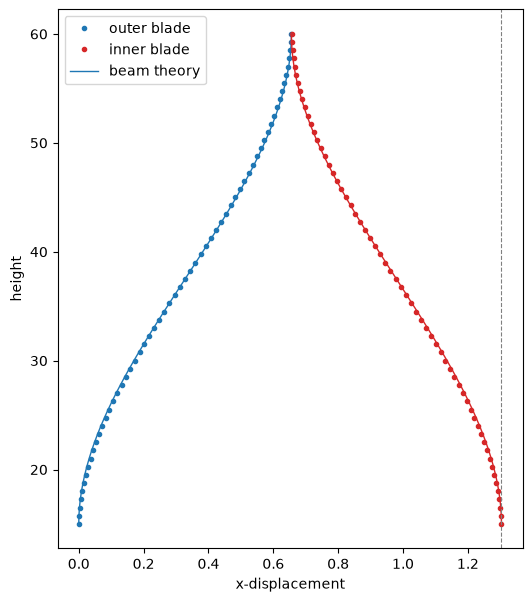

In [11]:
fig, ax = plt.subplots(figsize=(6, 7))
ax.plot(outer, heights, "o", ms=3, color="tab:blue", label="outer blade")
ax.plot(inner, heights, "o", ms=3, color="tab:red", label="inner blade")
ax.plot([top * s_curve((y - b) / L) for y in heights], heights, color="tab:blue", lw=1, label="beam theory")
ax.plot([top + (ux - top) * s_curve((H - b - y) / L) for y in heights], heights, color="tab:red", lw=1)
ax.axvline(ux, color="gray", ls="--", lw=0.8)
ax.set_xlabel("x-displacement")
ax.set_ylabel("height")
ax.legend()
plt.show()

## The stage moving

The force is swept from −10 N to 10 N, and for every step, the displacement of the left and the right end of the
stage is recorded. Moving along x, both ends should keep their height, giving two flat lines on top of each other. In
linear elasticity everything scales with the force, so the lines are straight. The small second-order rise that a
single parallelogram shows, and the double one cancels, needs a geometrically nonlinear solve.

In [12]:
ends = {"left end": (x_i + 2, y_s + 1, depth / 2), "right end": (W - x_i - 2, y_s + 1, depth / 2)}
paths = {name: [] for name in ends}
state = ngs.GridFunction(fes)
for step in range(-10, 11):
    state.vec.data = inverse * (step / 10 * f.vec)
    for name, point in ends.items():
        dx, dy, dz = state(mesh(*point))
        paths[name].append((dx, dy))
for name, path in paths.items():
    print(name, "largest y-displacement", f"{max(abs(d[1]) for d in path):.2e}", "over a travel of",
          round(max(abs(d[0]) for d in path), 3))

left end largest y-displacement 5.15e-04 over a travel of 1.304
right end largest y-displacement 5.21e-04 over a travel of 1.304


The paths at true scale are flat, and the y-displacement magnified in µm shows what is left of it:

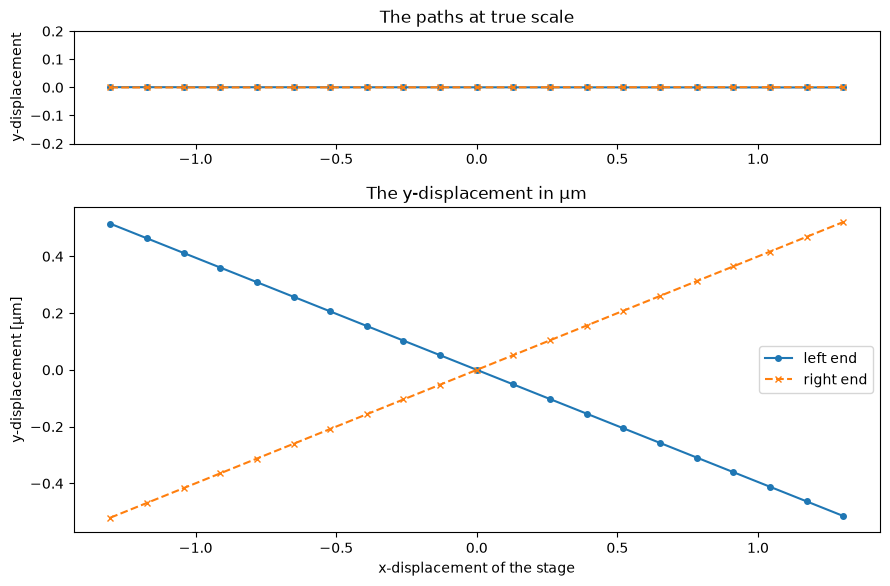

In [13]:
fig, (ax, zoom) = plt.subplots(2, 1, figsize=(9, 6), gridspec_kw={"height_ratios": (1, 2)})
for (name, path), style in zip(paths.items(), ("o-", "x--")):
    xs = [d[0] for d in path]
    ax.plot(xs, [d[1] for d in path], style, ms=4, label=name)
    zoom.plot(xs, [1000 * d[1] for d in path], style, ms=4, label=name)
ax.set_aspect("equal")
ax.set_ylim(-0.2, 0.2)
ax.set_title("The paths at true scale")
ax.set_ylabel("y-displacement")
zoom.set_title("The y-displacement in µm")
zoom.set_xlabel("x-displacement of the stage")
zoom.set_ylabel("y-displacement [µm]")
zoom.legend()
fig.tight_layout()
plt.show()

In [14]:
from ngsolve.webgui import Draw as WebguiDraw
import sys
sys.path.insert(0, "..")
from gallery import save_scene, save_figure, HIDDEN, CLEAN
save_scene(WebguiDraw(ngs.Norm(disp), mesh, deformation=disp * 3, settings={**CLEAN, "Colormap": {"ncolors": 32}}, show=False), "flexure")